# Module 08: Initialization, Regularization, Normalization, and Stabilization

This module teaches how deep networks are made trainable and reliable. Optimizers update weights, but initialization, regularization, normalization, and stabilization decide whether gradients flow well and whether the model generalizes.


## Module outline

* **Step 1: Why Stabilization Matters**
  * activation scale, gradient scale, exploding/vanishing signals.
* **Step 2: Fan-In, Fan-Out, and Variance**
  * definitions, why weight scale depends on layer size.
* **Step 3: Initialization Methods**
  * small random, Xavier/Glorot, He/Kaiming, LeCun, orthogonal, LSUV, Fixup.
* **Step 4: L1, L2, Weight Decay, and AdamW**
  * penalties, sparsity, shrinkage, decoupled decay.
* **Step 5: Dropout Family**
  * dropout, spatial dropout, DropBlock, attention dropout, train/eval behavior.
* **Step 6: Data Augmentation**
  * label-preserving transformations, MixUp, CutMix, RandAugment, task-specific risks.
* **Step 7: Batch Normalization**
  * batch statistics, running statistics, train/eval mode, small-batch issues.
* **Step 8: LayerNorm, RMSNorm, GroupNorm, InstanceNorm**
  * axes, where each is used, transformer/CNN differences.
* **Step 9: Residual Connections and Deep Stability**
  * residual blocks, pre-activation, pre-norm, ReZero, residual scaling.
* **Step 10: Label Smoothing, EMA, SWA, Stochastic Depth**
  * confidence, averaging, deep regularization.
* **Step 11: Robustness and Adversarial Stabilization**
  * noise injection, adversarial examples, gradient clipping connection.
* **Step 12: Stabilization Debugging Checklist**
  * activation histograms, gradient histograms, train/eval mode, NaN checks.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 10
rng = np.random.default_rng(42)


## Step 1: Why Stabilization Matters

**Definition:** Stabilization means keeping activations, gradients, and updates in a useful numeric range so the network can train.

Deep networks repeatedly multiply by weights and apply nonlinearities. If the signal shrinks each layer, learning vanishes. If the signal grows each layer, activations and gradients explode.


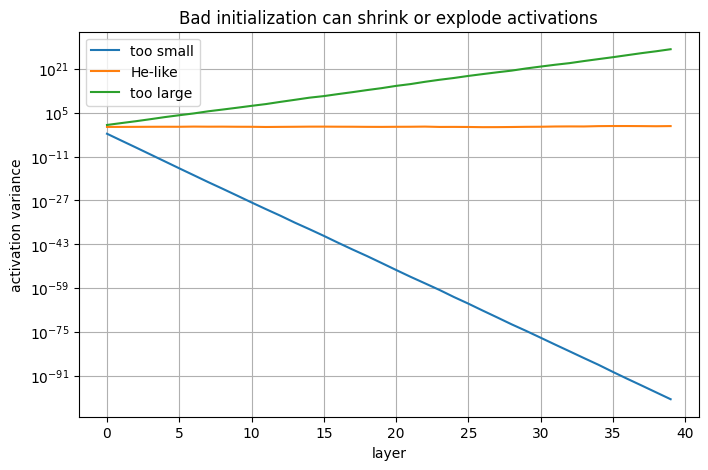

In [2]:
width, depth, samples = 256, 40, 512
X = rng.normal(size=(samples, width))
scales = [0.005, np.sqrt(2/width), 0.2]
labels = ['too small', 'He-like', 'too large']
for scale, label in zip(scales, labels):
    A = X.copy()
    vars_ = []
    for _ in range(depth):
        W = rng.normal(scale=scale, size=(width,width))
        A = np.maximum(0, A @ W)
        vars_.append(A.var())
    plt.plot(vars_, label=label)
plt.yscale('log')
plt.title('Bad initialization can shrink or explode activations')
plt.xlabel('layer'); plt.ylabel('activation variance'); plt.legend();


## Step 2: Fan-In, Fan-Out, and Variance

**Definitions:**

* **Fan-in:** number of input connections to a neuron.
* **Fan-out:** number of output connections from a layer.

Initialization uses fan-in/fan-out because a neuron sums many weighted inputs. More inputs need smaller weight variance to keep output scale stable.


In [3]:
layers = pd.DataFrame({
    'layer':['dense 100->50','dense 512->512','conv 3x3, 32->64'],
    'fan_in':[100,512,3*3*32],
    'fan_out':[50,512,3*3*64],
})
layers['xavier_std'] = np.sqrt(2/(layers.fan_in + layers.fan_out))
layers['he_std'] = np.sqrt(2/layers.fan_in)
display(layers)


,layer,fan_in,fan_out,xavier_std,he_std
0,dense 100->50,100,50,0.115470,0.141421
1,dense 512->512,512,512,0.044194,0.062500
2,"conv 3x3, 32->64",288,576,0.048113,0.083333


## Step 3: Initialization Methods

| Method | Definition | Where it is used |
|---|---|---|
| small random | weights sampled near zero | simple demos, but often weak for deep nets |
| Xavier / Glorot | variance based on fan-in and fan-out | tanh/sigmoid-like networks |
| He / Kaiming | variance based on fan-in | ReLU/GELU-like networks |
| LeCun | variance suited for SELU/self-normalizing nets | SELU networks |
| orthogonal | weight matrices with orthogonal structure | RNNs and deep nets sometimes |
| LSUV | layer-sequential unit-variance initialization | data-dependent initialization |
| Fixup | initialization strategy for residual networks without normalization | specialized residual training |

**Common mistake:** using one initializer for every activation and architecture.


## Step 4: L1, L2, Weight Decay, and AdamW

**L1 definition:** adds penalty proportional to absolute weight values.

$$L_{total}=L+\lambda\sum |w|$$

L1 can encourage sparse weights.

**L2 definition:** adds penalty proportional to squared weight values.

$$L_{total}=L+\lambda\sum w^2$$

L2 discourages large weights.

**Weight decay:** directly shrinks weights during update.

**AdamW:** decouples weight decay from Adam's adaptive gradient scaling.


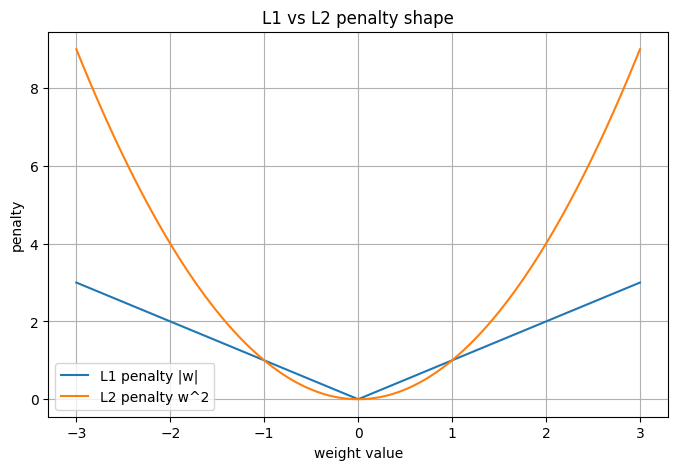

In [4]:
w = np.linspace(-3,3,300)
l1 = np.abs(w)
l2 = w**2
plt.plot(w,l1,label='L1 penalty |w|')
plt.plot(w,l2,label='L2 penalty w^2')
plt.title('L1 vs L2 penalty shape')
plt.xlabel('weight value'); plt.ylabel('penalty'); plt.legend();


## Step 5: Dropout Family

**Dropout definition:** randomly set some activations to zero during training.

Why it helps:

* reduces co-adaptation;
* acts like training many subnetworks;
* can reduce overfitting.

Variants:

| Variant | Meaning | Common use |
|---|---|---|
| dropout | drops individual activations | dense layers |
| spatial dropout | drops entire channels/maps | CNNs |
| DropBlock | drops contiguous regions | CNN feature maps |
| attention dropout | drops attention weights | transformers |
| stochastic depth | randomly skips residual blocks | deep ResNets/ViTs |

**Important:** dropout behaves differently in training and evaluation.


,unit,mask_keep,train_activation_after_inverted_dropout
0,0,0,0.000000
1,1,1,1.666667
2,2,0,0.000000
3,3,1,1.666667
4,4,1,1.666667
5,5,0,0.000000
6,6,0,0.000000
7,7,0,0.000000
8,8,1,1.666667
9,9,1,1.666667


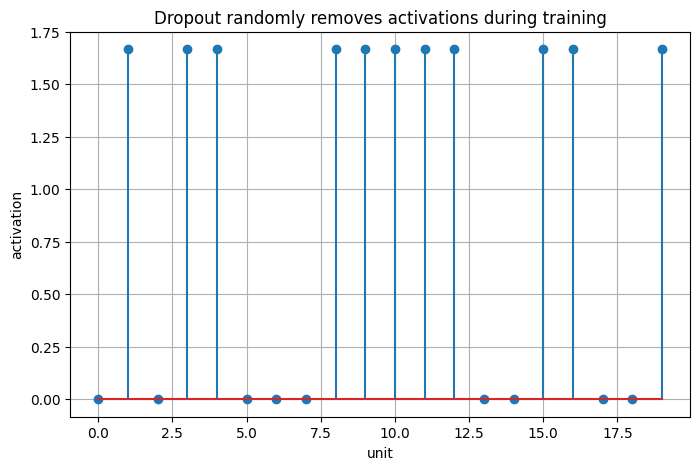

In [5]:
activations = np.ones(20)
drop_prob = 0.4
mask = rng.random(20) > drop_prob
dropped = activations * mask / (1-drop_prob)
display(pd.DataFrame({'unit':np.arange(20),'mask_keep':mask.astype(int),'train_activation_after_inverted_dropout':dropped}))
plt.stem(dropped)
plt.title('Dropout randomly removes activations during training')
plt.xlabel('unit'); plt.ylabel('activation');


## Step 6: Data Augmentation

**Definition:** Data augmentation creates modified training examples while preserving the correct label.

Examples:

| Data type | Good augmentations | Dangerous augmentations |
|---|---|---|
| natural image | crop, horizontal flip, color jitter | vertical flip if orientation matters |
| digit image | small shift/rotation | rotation turning 6 into 9 |
| text | synonym/back-translation carefully | changing sentiment meaning |
| audio | noise, time shift | removing key event |

Advanced image augmentations include MixUp, CutMix, RandAugment, AutoAugment, and Cutout.


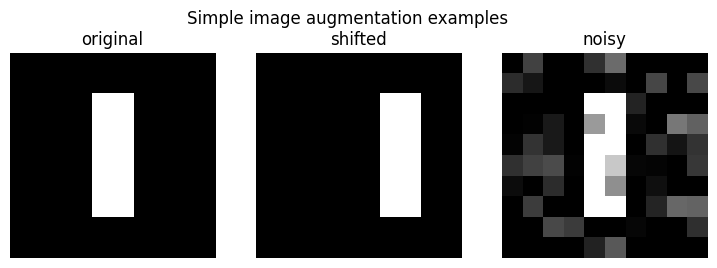

In [6]:
img = np.zeros((10,10))
img[2:8,4:6] = 1
shifted = np.roll(img, shift=2, axis=1)
noisy = np.clip(img + rng.normal(scale=.2, size=img.shape),0,1)
fig, axes = plt.subplots(1,3,figsize=(9,3))
for ax, im, title in zip(axes,[img,shifted,noisy],['original','shifted','noisy']):
    ax.imshow(im,cmap='gray'); ax.set_title(title); ax.axis('off')
plt.suptitle('Simple image augmentation examples');


## Step 7: Batch Normalization

**Definition:** BatchNorm normalizes activations using mean and variance computed over the batch, then applies learned scale and shift.

During training:

$$\hat{x}=\frac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}}$$

During inference, BatchNorm uses running mean and running variance collected during training.

**Where used:** CNNs and some MLPs.

**Common mistake:** forgetting train/eval mode. BatchNorm behaves differently in each.


In [7]:
batch = rng.normal(loc=5, scale=3, size=(8,4))
mu = batch.mean(axis=0)
var = batch.var(axis=0)
bn = (batch-mu)/np.sqrt(var+1e-5)
display(pd.DataFrame({
    'feature':[0,1,2,3],
    'before_mean':mu,
    'before_var':var,
    'after_mean':bn.mean(axis=0),
    'after_var':bn.var(axis=0)
}))


,feature,before_mean,before_var,after_mean,after_var
0,0,6.153323,13.854945,-1.110223e-16,0.999999
1,1,3.965421,6.408740,0.000000e+00,0.999998
2,2,3.912331,5.886025,2.775558e-17,0.999998
3,3,5.970568,5.993598,1.942890e-16,0.999998


## Step 8: LayerNorm, RMSNorm, GroupNorm, InstanceNorm

Normalization methods differ mainly by which axes they normalize.

| Method | Normalizes over | Common use |
|---|---|---|
| BatchNorm | batch axis and sometimes spatial axes | CNNs with decent batch size |
| LayerNorm | features inside each example | transformers and RNNs |
| RMSNorm | root mean square of features, no mean subtraction | modern LLMs |
| GroupNorm | groups of channels | small-batch vision |
| InstanceNorm | each channel per example | style transfer / image generation |

**Core idea:** normalization is not one concept with one axis. The axis choice changes behavior.


In [8]:
x = rng.normal(loc=4, scale=2, size=(3,5))  # 3 examples, 5 features
layer_norm = (x - x.mean(axis=1, keepdims=True)) / np.sqrt(x.var(axis=1, keepdims=True)+1e-5)
rms_norm = x / np.sqrt(np.mean(x*x, axis=1, keepdims=True)+1e-5)
display(pd.DataFrame({
    'example':[0,1,2],
    'original_mean':x.mean(axis=1),
    'layernorm_mean':layer_norm.mean(axis=1),
    'rmsnorm_rms':np.sqrt(np.mean(rms_norm*rms_norm, axis=1))
}))


,example,original_mean,layernorm_mean,rmsnorm_rms
0,0,4.873300,3.108624e-16,1.0
1,1,5.682247,-8.881784e-17,1.0
2,2,3.027465,3.108624e-16,1.0


## Step 9: Residual Connections and Deep Stability

**Definition:** A residual connection adds a shortcut path:

$$y=F(x)+x$$

This lets information and gradients flow through deep networks more easily.

Where used:

* ResNets;
* transformers;
* many modern CNNs and diffusion U-Nets.

Variants:

* post-activation residual block;
* pre-activation ResNet block;
* pre-norm transformer block;
* residual scaling;
* ReZero.

**Common mistake:** adding tensors with incompatible shapes.


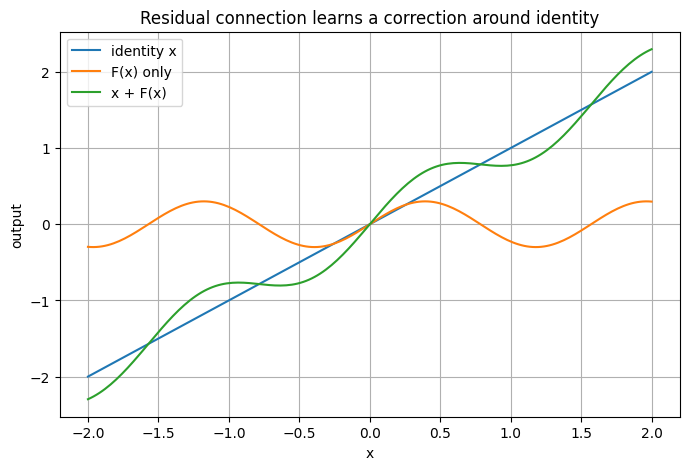

In [9]:
x = np.linspace(-2,2,200)
F = 0.3*np.sin(4*x)
y_no_residual = F
y_residual = x + F
plt.plot(x, x, label='identity x')
plt.plot(x, y_no_residual, label='F(x) only')
plt.plot(x, y_residual, label='x + F(x)')
plt.title('Residual connection learns a correction around identity')
plt.xlabel('x'); plt.ylabel('output'); plt.legend();


## Step 10: Label Smoothing, EMA, SWA, and Stochastic Depth

### Label smoothing

Softens one-hot labels. Instead of `[0, 0, 1, 0]`, use something like `[0.025, 0.025, 0.925, 0.025]`.

It can reduce overconfidence.

### EMA

Exponential Moving Average keeps a smoothed copy of model weights.

### SWA

Stochastic Weight Averaging averages weights across later training checkpoints to find flatter solutions.

### Stochastic depth

Randomly skips residual blocks during training. It regularizes very deep networks.


In [10]:
num_classes = 5
true_class = 2
smooth = 0.1
one_hot = np.zeros(num_classes); one_hot[true_class] = 1
smoothed = np.ones(num_classes)*smooth/(num_classes-1); smoothed[true_class] = 1-smooth
display(pd.DataFrame({'class':np.arange(num_classes),'one_hot':one_hot,'label_smoothed':smoothed}))


,class,one_hot,label_smoothed
0,0,0.0,0.025
1,1,0.0,0.025
2,2,1.0,0.900
3,3,0.0,0.025
4,4,0.0,0.025


## Step 11: Robustness and Adversarial Stabilization

**Noise injection:** add small random noise to inputs, weights, or activations during training.

**Adversarial training:** train on small worst-case perturbations that try to fool the model.

**Why it matters:** ordinary validation may not show fragility to small input changes.

**Common mistake:** assuming augmentation and adversarial robustness are the same. Augmentation uses chosen transformations; adversarial examples are selected to maximize model error.


## Step 12: Stabilization Debugging Checklist

When training is unstable, check:

| Symptom | What to inspect |
|---|---|
| loss is NaN | learning rate, mixed precision, invalid labels, exploding gradients |
| activations become zero | dead ReLU, bad initialization, bad normalization |
| activations explode | initialization scale, missing normalization, LR too high |
| train/eval mismatch | dropout and BatchNorm mode |
| validation much worse | overfitting, leakage, augmentation mismatch |
| gradients vanish | activation saturation, depth, initialization |
| gradients explode | LR, sequence length, residual scaling, clipping |

**Best practice:** plot activation histograms and gradient norms before randomly changing techniques.


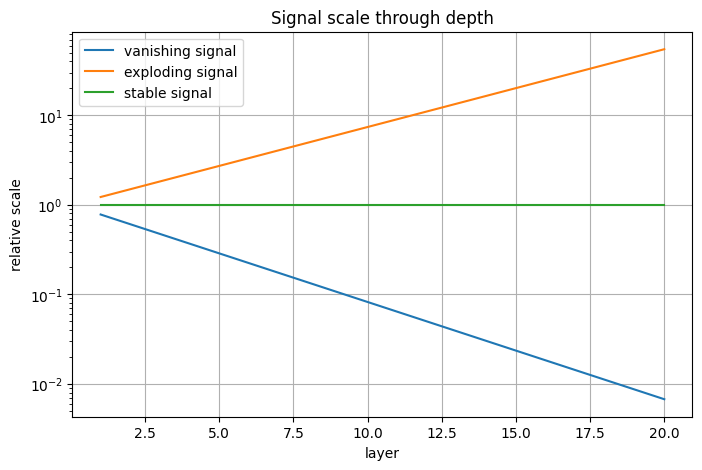

In [11]:
layers = np.arange(1,21)
vanish = np.exp(-layers/4)
explode = np.exp(layers/5)
stable = np.ones_like(layers)
plt.plot(layers, vanish, label='vanishing signal')
plt.plot(layers, explode, label='exploding signal')
plt.plot(layers, stable, label='stable signal')
plt.yscale('log')
plt.title('Signal scale through depth')
plt.xlabel('layer'); plt.ylabel('relative scale'); plt.legend();


## Step 13: Initialization Master Lab

Initialization should be judged by how activations and gradients behave through depth. The same model can train or fail depending only on initial scale.


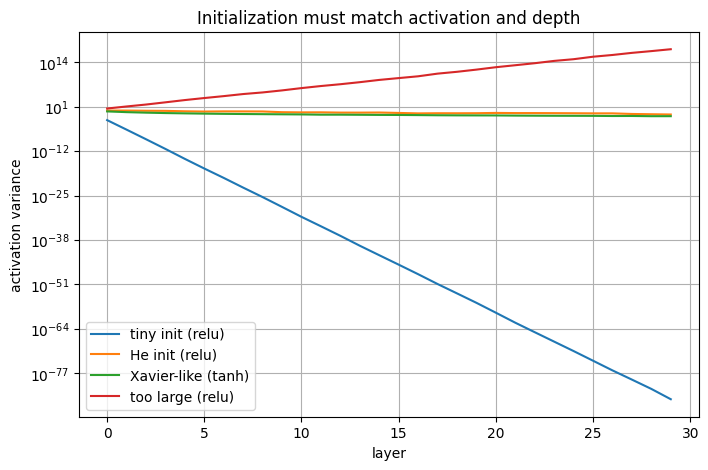

In [12]:
def activation_variances(scale, activation='relu', depth=30, width=128, samples=256):
    A = rng.normal(size=(samples,width))
    vars_ = []
    for _ in range(depth):
        W = rng.normal(scale=scale, size=(width,width))
        Z = A @ W
        if activation == 'relu':
            A = np.maximum(0,Z)
        elif activation == 'tanh':
            A = np.tanh(Z)
        vars_.append(A.var())
    return vars_

width=128
configs = [
    ('tiny init',0.005,'relu'),
    ('He init',np.sqrt(2/width),'relu'),
    ('Xavier-like',np.sqrt(1/width),'tanh'),
    ('too large',0.25,'relu')
]
for name,scale,act in configs:
    plt.plot(activation_variances(scale, act), label=f'{name} ({act})')
plt.yscale('log')
plt.title('Initialization must match activation and depth')
plt.xlabel('layer'); plt.ylabel('activation variance'); plt.legend();


## Step 14: Regularization Strength Lab

Too little regularization can overfit. Too much regularization can underfit. The goal is not maximum regularization; the goal is best validation behavior.


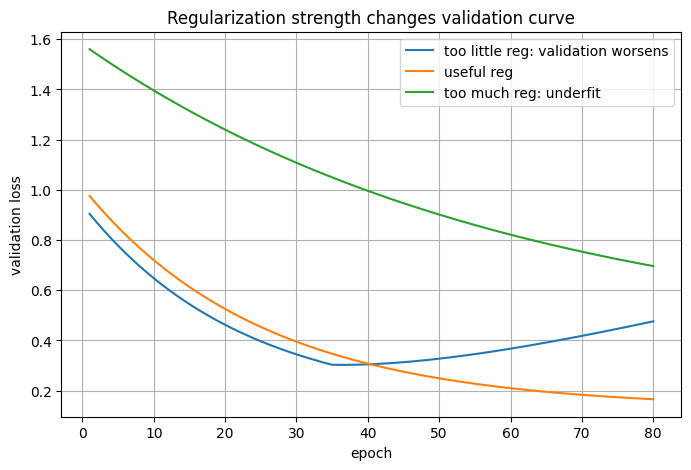

In [13]:
epochs=np.arange(1,81)
no_reg_train=.95*np.exp(-epochs/18)+.03
no_reg_val=.8*np.exp(-epochs/22)+.14+.007*np.maximum(epochs-35,0)
good_reg_train=1.05*np.exp(-epochs/24)+.08
good_reg_val=.88*np.exp(-epochs/25)+.13
too_reg_train=1.2*np.exp(-epochs/60)+.35
too_reg_val=1.2*np.exp(-epochs/60)+.38
plt.plot(epochs,no_reg_val,label='too little reg: validation worsens')
plt.plot(epochs,good_reg_val,label='useful reg')
plt.plot(epochs,too_reg_val,label='too much reg: underfit')
plt.title('Regularization strength changes validation curve')
plt.xlabel('epoch'); plt.ylabel('validation loss'); plt.legend();


## Step 15: Dropout Train vs Eval Calculation

In inverted dropout, training activations are scaled by `1/(1-p)` after dropping units. At evaluation time, dropout is disabled.


In [14]:
p=0.5
a=np.array([2.,2.,2.,2.])
mask=np.array([1,0,1,0])
train_out=a*mask/(1-p)
eval_out=a
display(pd.DataFrame({'unit':[0,1,2,3],'input':a,'dropout_mask':mask,'train_output':train_out,'eval_output':eval_out}))


,unit,input,dropout_mask,train_output,eval_output
0,0,2.0,1,4.0,2.0
1,1,2.0,0,0.0,2.0
2,2,2.0,1,4.0,2.0
3,3,2.0,0,0.0,2.0


## Step 16: Normalization Axis Lab

BatchNorm and LayerNorm can produce different outputs because they normalize different axes.


In [15]:
Xn = np.array([[1.,2.,3.],[10.,11.,12.],[20.,22.,24.]])
batch_norm = (Xn - Xn.mean(axis=0, keepdims=True))/np.sqrt(Xn.var(axis=0, keepdims=True)+1e-5)
layer_norm = (Xn - Xn.mean(axis=1, keepdims=True))/np.sqrt(Xn.var(axis=1, keepdims=True)+1e-5)
print('original:\n',Xn)
print('BatchNorm-like over batch axis:\n',np.round(batch_norm,2))
print('LayerNorm-like over feature axis:\n',np.round(layer_norm,2))


original:
 [[ 1.  2.  3.]
 [10. 11. 12.]
 [20. 22. 24.]]
BatchNorm-like over batch axis:
 [[-1.2  -1.18 -1.16]
 [-0.04 -0.08 -0.12]
 [ 1.25  1.26  1.28]]
LayerNorm-like over feature axis:
 [[-1.22  0.    1.22]
 [-1.22  0.    1.22]
 [-1.22  0.    1.22]]


**Output meaning:** BatchNorm compares examples feature-by-feature. LayerNorm normalizes each example internally. This is why BatchNorm fits CNN batches and LayerNorm fits transformers.


## Step 17: Residual Gradient Intuition

For a plain stack, gradients must pass through every layer transformation. For a residual block:

$$y=x+F(x)$$

the derivative includes an identity path:

$$\frac{dy}{dx}=1+F'(x)$$

That `1` helps gradients flow even when $F'(x)$ is small.


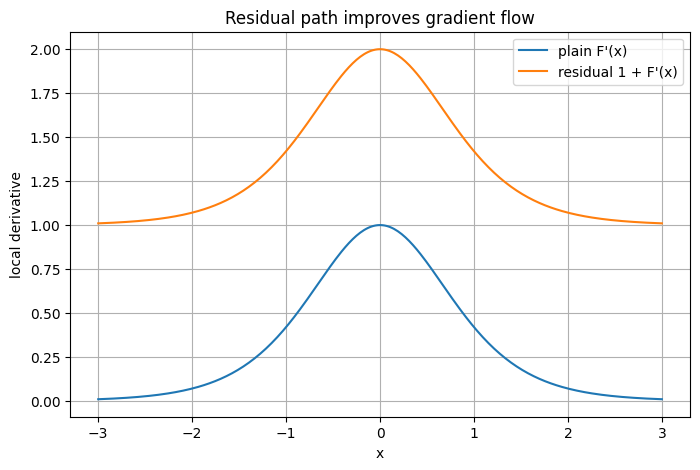

In [16]:
x=np.linspace(-3,3,300)
F=np.tanh(x)
dF=1-np.tanh(x)**2
plain_grad=dF
residual_grad=1+dF
plt.plot(x,plain_grad,label="plain F'(x)")
plt.plot(x,residual_grad,label="residual 1 + F'(x)")
plt.title('Residual path improves gradient flow')
plt.xlabel('x'); plt.ylabel('local derivative'); plt.legend();


## Step 18: Augmentation Decision Table

| Task | Useful augmentation | Bad augmentation |
|---|---|---|
| cat/dog image | crop, horizontal flip, color jitter | label-destroying extreme crop |
| digit recognition | small shift, small rotation | 180° rotation |
| medical X-ray | mild intensity/position changes | transformations invalid for anatomy |
| sentiment text | careful paraphrase | replacing words that flip sentiment |
| speech command | background noise, time shift | cutting out command word |

Augmentation is not decoration; it encodes what invariances the model should learn.


## Step 19: Stabilization Technique Selection

| Symptom | Try first |
|---|---|
| activations vanish | better initialization, normalization, residuals |
| gradients explode | lower LR, clipping, normalization, residual scaling |
| train good, val bad | augmentation, weight decay, dropout, label smoothing |
| small batch CNN unstable | GroupNorm instead of BatchNorm |
| transformer unstable early | warmup, pre-norm, AdamW, gradient clipping |
| overconfident classifier | label smoothing, calibration, augmentation |


## Step 20: Module 08 Practical Checklist

Before saying a model architecture is bad, check:

* initializer matches activation;
* activations are not exploding/vanishing;
* normalization axes are correct;
* train/eval mode is correct;
* dropout is not active during evaluation;
* weight decay is not applied to norm/bias parameters blindly;
* augmentation preserves labels;
* residual shapes match;
* gradients are finite;
* validation curve supports the chosen regularization.


## Module 08 Summary

Stabilization is the set of methods that make deep networks trainable and generalizable. Initialization controls starting signal scale. Regularization controls overfitting. Normalization controls activation statistics. Residual connections improve information and gradient flow. Augmentation and smoothing improve robustness. Debugging requires checking activation scale, gradient scale, train/eval mode, and validation behavior.
